In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
import seaborn as sns 
from scipy import stats

import os,csv
import torch
from torch import nn
import torch.nn.functional as F
from pathlib import Path
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import r2_score
from pprint import pprint

from pn.CNN3D import *
import pn.p5_utils as p5u

# Style Decisions

9


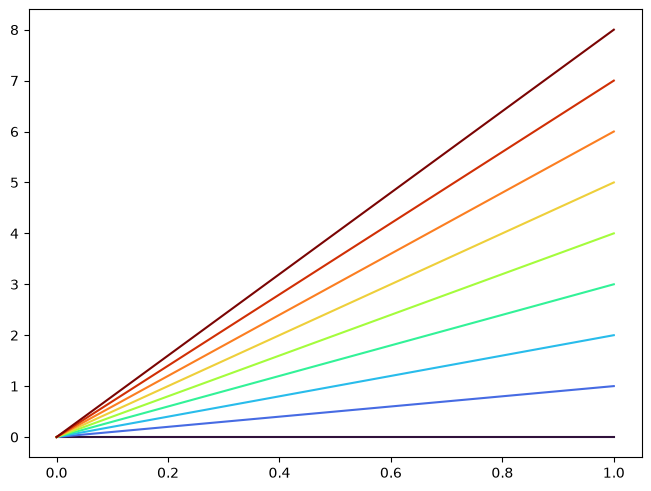

In [2]:
# pick a colormap
cmap = plt.get_cmap('turbo')
color_list = cmap(np.linspace(0,1,9))
fig, ax = plt.subplots(layout='constrained')

for i, color in enumerate(color_list):
    ax.plot([0, i], color=color_list[i])

print(len(color_list))
color_list = color_list[1:]

In [3]:
numIter = 20

# P1 (NSR-004-002)

In [3]:
# load data
config = Config(2)
train_loader, valid_loader, test_loader = get_dataloaders(config)

Using default channels, all inbound electrodes will be included.
Loading Train Files...
D:\Becca\Data\PN_preprocessed\NSR-004-002\Training block 1_green__loc4_7_1742409770184_250319_144250_hga.pt
D:\Becca\Data\PN_preprocessed\NSR-004-002\Training block 2_green__loc8_1_1742410047212_250319_144727_hga.pt
D:\Becca\Data\PN_preprocessed\NSR-004-002\Training block 3_green__loc4_3_1742410337516_250319_145217_hga.pt
Loading Val Files...
D:\Becca\Data\PN_preprocessed\NSR-004-002\Validation block_green_loc8_2_1742410614837_250319_145654_hga.pt
Loading Test Files...
D:\Becca\Data\PN_preprocessed\NSR-004-002\Validation block_green_loc8_2_1742410614837_250319_145654_hga.pt


In [7]:
p1_r2 = []
p1_pmse = []
for rep in range(numIter):
    print("------------------------")
    print(f'Iter {rep+1}')
    # make model
    model = CNN2D_LSTM(config)
    optimizer = torch.optim.Adam(model.parameters(), lr=config.learning_rate, weight_decay=config.weight_decay)
    criterion = torch.nn.MSELoss(reduction='sum')
    
    # train
    CNN3D_train(model, optimizer, criterion, config, train_loader, valid_loader)

    tgts2, preds2 = CNN3D_predict(model, test_loader)

    p1_r2.append(r2_score(tgts2, preds2))
    p1_pmse.append(np.mean(np.linalg.norm(tgts2 - preds2,axis=1)**2)/2)
    print("------------------------")


------------------------
Iter 1
Epoch 0/30: train:14.351445633476063  val:18.73859601020813
Epoch 1/30: train:5.604482380010314  val:18.670569229125977
Epoch 2/30: train:3.454246474524676  val:12.886629104614258
Epoch 3/30: train:2.4707860210436885  val:11.619644379615783
Epoch 4/30: train:1.781631369711989  val:11.756723713874816
Epoch 5/30: train:1.3762657865250514  val:11.10196328163147
Epoch 6/30: train:1.0951266623244196  val:11.344579553604126
Epoch 7/30: train:0.9516501989910158  val:11.542710256576537
Epoch 8/30: train:0.8381026699128797  val:10.275201106071473
Epoch 9/30: train:0.7187961318482787  val:10.204058241844177
Epoch 10/30: train:0.6806583028223555  val:11.71293785572052
Epoch 11/30: train:0.5796098214084819  val:10.269256949424744
Epoch 12/30: train:0.5120117380204847  val:10.160691058635711
Epoch 13/30: train:0.46560283914460976  val:10.639177536964416
Epoch 14/30: train:0.4398966548427687  val:10.383355152606963
Epoch 15/30: train:0.4198953859444897  val:10.7431872

In [12]:
r2_res = stats.bootstrap((np.asarray(p1_r2),), np.median, confidence_level=0.95,
                      n_resamples=10000, method='BCa', random_state=0)
print(r2_res.confidence_interval)   # ConfidenceInterval(low=..., high=...)
print(f'Median R2: {np.median(np.asarray(p1_r2))}')
pmse_res = stats.bootstrap((np.asarray(p1_pmse),), np.median, confidence_level=0.95,
                      n_resamples=10000, method='BCa', random_state=0)
print(pmse_res.confidence_interval)   # ConfidenceInterval(low=..., high=...)
print(f'Median %mse: {np.median(np.asarray(p1_pmse))}')


ConfidenceInterval(low=np.float64(0.6758368611335754), high=np.float64(0.6900409460067749))
Median R2: 0.6864368617534637
ConfidenceInterval(low=np.float32(0.08273682), high=np.float32(0.08730902))
Median %mse: 0.08454285562038422


In [6]:
offline_2 = r2_score(tgts2,preds2)
print(f"R2 {offline_2}")

error = np.linalg.norm(tgts2 - preds2,axis=1)
se = error**2
mse = np.mean(se)
p1_pmse = mse/2 
print("% mse {mse/2}")


R2 0.6790422797203064
% mse {mse/2}


# P2 (NSR-004-003)

In [13]:
# load data
config = Config(3)
train_loader, valid_loader, test_loader = get_dataloaders(config)

Using default channels, all inbound electrodes will be included.
Loading Train Files...
D:\Becca\Data\PN_preprocessed\NSR-004-003\Training block 1_FIH0050blue__loc4_6_1744227575794_250409_153935_hga.pt
D:\Becca\Data\PN_preprocessed\NSR-004-003\Training block 2_FIH0050blue__loc8_2_1744227839734_250409_154359_hga.pt
D:\Becca\Data\PN_preprocessed\NSR-004-003\Training block 3_FIH0050blue__loc4_2_1744228097783_250409_154817_hga.pt
Loading Val Files...
D:\Becca\Data\PN_preprocessed\NSR-004-003\Validation block_FIH0050blue_loc8_3_1744228487511_250409_155447_hga.pt
Loading Test Files...
D:\Becca\Data\PN_preprocessed\NSR-004-003\Validation block_FIH0050blue_loc8_3_1744228487511_250409_155447_hga.pt


In [14]:
p2_r2 = []
p2_pmse = []
for rep in range(numIter):
    print("------------------------")
    print(f'Iter {rep+1}')
    # make model
    model = CNN2D_LSTM(config)
    optimizer = torch.optim.Adam(model.parameters(), lr=config.learning_rate, weight_decay=config.weight_decay)
    criterion = torch.nn.MSELoss(reduction='sum')
    
    # train
    CNN3D_train(model, optimizer, criterion, config, train_loader, valid_loader)

    tgts3, preds3 = CNN3D_predict(model, test_loader)

    p2_r2.append(r2_score(tgts3, preds3))
    p2_pmse.append(np.mean(np.linalg.norm(tgts3 - preds3,axis=1)**2)/2)
    print("------------------------")


------------------------
Iter 1
Epoch 0/30: train:9.298666724870944  val:7.839132606983185
Epoch 1/30: train:2.2297040008265396  val:6.468339943885804
Epoch 2/30: train:1.2283975790286887  val:5.891501939296722
Epoch 3/30: train:0.8797890297297773  val:5.499648296833039
Epoch 4/30: train:0.6835018522266684  val:5.206267309188843
Epoch 5/30: train:0.594493400947801  val:4.94007693529129
Epoch 6/30: train:0.49383227270225  val:4.4935522198677065
Epoch 7/30: train:0.40177256151519974  val:4.470310640335083
Epoch 8/30: train:0.37784055684661044  val:4.064422237873077
Epoch 9/30: train:0.3198211370999443  val:3.9986241817474366
Epoch 10/30: train:0.3168209760353483  val:3.800314795970917
Epoch 11/30: train:0.27594480740612953  val:4.053247582912445
Epoch 12/30: train:0.2502824509323671  val:3.7034067034721376
Epoch 13/30: train:0.2380310222506523  val:3.5836772084236146
Epoch 14/30: train:0.22719938654837937  val:3.70594927072525
Epoch 15/30: train:0.22071516372520347  val:3.612940126657486

In [15]:
r2_res = stats.bootstrap((np.asarray(p2_r2),), np.median, confidence_level=0.95,
                      n_resamples=10000, method='BCa', random_state=0)
print(r2_res.confidence_interval)   # ConfidenceInterval(low=..., high=...)
print(f'Median R2: {np.median(np.asarray(p2_r2))}')
pmse_res = stats.bootstrap((np.asarray(p2_pmse),), np.median, confidence_level=0.95,
                      n_resamples=10000, method='BCa', random_state=0)
print(pmse_res.confidence_interval)   # ConfidenceInterval(low=..., high=...)
print(f'Median %mse: {np.median(np.asarray(p2_pmse))}')


ConfidenceInterval(low=np.float64(0.7925587594509125), high=np.float64(0.8076314628124237))
Median R2: 0.7986950874328613
ConfidenceInterval(low=np.float32(0.024929654), high=np.float32(0.026443882))
Median %mse: 0.025483399629592896


In [9]:
tgts3, preds3 = CNN3D_predict(model, test_loader)

offline_3 = r2_score(tgts3,preds3)
print(f"R2 {offline_3}")

error = np.linalg.norm(tgts3 - preds3,axis=1)
se = error**2
mse = np.mean(se)
p2_pmse = mse/2
print(f"% mse {mse/2}")


R2 0.7994914054870605
% mse 0.024615949019789696


# P3 (NSR-004-004)

In [16]:
# load data
config = Config(4)
train_loader, valid_loader, test_loader = get_dataloaders(config)

Using default channels, all inbound electrodes will be included.
Loading Train Files...
D:\Becca\Data\PN_preprocessed\NSR-004-004\center-out-easy-block1_FIH0068__1_1753286802143_250723_160642_hga.pt
D:\Becca\Data\PN_preprocessed\NSR-004-004\center-out-easy-block2_FIH0068__1_1753287064855_250723_161104_hga.pt
D:\Becca\Data\PN_preprocessed\NSR-004-004\center-out-easy-block3_FIH0068__3_1753287429688_250723_161709_hga.pt
Loading Val Files...
D:\Becca\Data\PN_preprocessed\NSR-004-004\center-out-easy-block4_FIH0068__1_1753288012531_250723_162652_hga.pt
Loading Test Files...
D:\Becca\Data\PN_preprocessed\NSR-004-004\center-out-easy-block4_FIH0068__1_1753288012531_250723_162652_hga.pt


In [17]:
p3_r2 = []
p3_pmse = []
for rep in range(numIter):
    print("------------------------")
    print(f'Iter {rep+1}')
    # make model
    model = CNN2D_LSTM(config)
    optimizer = torch.optim.Adam(model.parameters(), lr=config.learning_rate, weight_decay=config.weight_decay)
    criterion = torch.nn.MSELoss(reduction='sum')
    
    # train
    CNN3D_train(model, optimizer, criterion, config, train_loader, valid_loader)

    tgts4, preds4 = CNN3D_predict(model, test_loader)

    p3_r2.append(r2_score(tgts4, preds4))
    p3_pmse.append(np.mean(np.linalg.norm(tgts4 - preds4,axis=1)**2)/2)
    print("------------------------")


------------------------
Iter 1
Epoch 0/50: train:4.25029929100521  val:3.608668940407889
Epoch 1/50: train:3.015265432615129  val:3.974738768168858
Epoch 2/50: train:1.0146929546008034  val:2.3214225258146013
Epoch 3/50: train:0.5287274557446676  val:2.2010173825990584
Epoch 4/50: train:0.36567151357257177  val:2.0743498291288103
Epoch 5/50: train:0.28063622400874183  val:1.89787000701541
Epoch 6/50: train:0.25022521023712463  val:1.8511439973399753
Epoch 7/50: train:0.21641085474264055  val:1.7978950228009904
Epoch 8/50: train:0.18430359200352714  val:1.783702132247743
Epoch 9/50: train:0.17227234218328719  val:1.7567560346353621
Epoch 10/50: train:0.16903485133061333  val:1.7136582533518474
Epoch 11/50: train:0.14625793730928785  val:1.613161448921476
Epoch 12/50: train:0.1292115898122863  val:1.6637604861032396
Epoch 13/50: train:0.12766428528324006  val:1.6071442195347376
Epoch 14/50: train:0.11728970540894403  val:1.6076810388337999
Epoch 15/50: train:0.1102507822806873  val:1.53

In [18]:
r2_res = stats.bootstrap((np.asarray(p3_r2),), np.median, confidence_level=0.95,
                      n_resamples=10000, method='BCa', random_state=0)
print(r2_res.confidence_interval)   # ConfidenceInterval(low=..., high=...)
print(f'Median R2: {np.median(np.asarray(p3_r2))}')
pmse_res = stats.bootstrap((np.asarray(p3_pmse),), np.median, confidence_level=0.95,
                      n_resamples=10000, method='BCa', random_state=0)
print(pmse_res.confidence_interval)   # ConfidenceInterval(low=..., high=...)
print(f'Median %mse: {np.median(np.asarray(p3_pmse))}')


ConfidenceInterval(low=np.float64(0.6238877773284912), high=np.float64(0.645602285861969))
Median R2: 0.639756441116333
ConfidenceInterval(low=np.float32(0.01139511), high=np.float32(0.012053886))
Median %mse: 0.011508877389132977


In [19]:
tgts4, preds4 = CNN3D_predict(model, test_loader)

offline_4 = r2_score(tgts4,preds4)
print(f"R2 {offline_4}")

error = np.linalg.norm(tgts4 - preds4,axis=1)
se = error**2
pmse4 = np.mean(se)/2

print(f"% mse {pmse4}")


R2 0.6432697772979736


NameError: name 'tgts3' is not defined

# P4 (NSR-004-005)

In [19]:
# load data
config = Config(5)
train_loader, valid_loader, test_loader = get_dataloaders(config)


Using default channels, all inbound electrodes will be included.
Loading Train Files...
D:\Becca\Data\PN_preprocessed\NSR-004-005\train-veasy-hover_FIH0093_webgrid_2_1765990632034_251217_165712_hga.pt
D:\Becca\Data\PN_preprocessed\NSR-004-005\train-veasy-hover_FIH0093_webgrid_3_1765990947075_251217_170227_hga.pt
D:\Becca\Data\PN_preprocessed\NSR-004-005\train-veasy-hover_FIH0093_webgrid_4_1765991292272_251217_170812_hga.pt
Loading Val Files...
D:\Becca\Data\PN_preprocessed\NSR-004-005\train-veasy-hover_FIH0093_webgrid_5_1765991611567_251217_171331_hga.pt
Loading Test Files...
D:\Becca\Data\PN_preprocessed\NSR-004-005\train-veasy-hover_FIH0093_webgrid_5_1765991611567_251217_171331_hga.pt


In [20]:
p4_r2 = []
p4_pmse = []
for rep in range(numIter):
    print("------------------------")
    print(f'Iter {rep+1}')
    # make model
    model = CNN2D_LSTM(config)
    optimizer = torch.optim.Adam(model.parameters(), lr=config.learning_rate, weight_decay=config.weight_decay)
    criterion = torch.nn.MSELoss(reduction='sum')
    
    # train
    CNN3D_train(model, optimizer, criterion, config, train_loader, valid_loader)

    tgts5, preds5 = CNN3D_predict(model, test_loader)

    p4_r2.append(r2_score(tgts5, preds5))
    p4_pmse.append(np.mean(np.linalg.norm(tgts5 - preds5,axis=1)**2)/2)
    print("------------------------")


------------------------
Iter 1
Epoch 0/50: train:12.912746242114476  val:13.416281756232767
Epoch 1/50: train:8.070673414639064  val:10.209773849038516
Epoch 2/50: train:5.9589629130704065  val:8.557552281547995
Epoch 3/50: train:4.203521681683404  val:7.1241097730748795
Epoch 4/50: train:2.9887401397739137  val:6.921608083388385
Epoch 5/50: train:2.2003619372844696  val:6.818751419291777
Epoch 6/50: train:1.672223231622151  val:6.256319200291353
Epoch 7/50: train:1.3144881395356995  val:6.501198193606208
Epoch 8/50: train:1.179429869566645  val:6.797316593282363
Epoch 9/50: train:1.115654115165983  val:6.810847114114201
Epoch 10/50: train:0.9993949436715671  val:6.249165619120879
Epoch 11/50: train:0.7641836277076176  val:6.245449122260599
Epoch 12/50: train:0.7280911579728127  val:6.3710490675533515
Epoch 13/50: train:0.655625719577074  val:5.792934305527631
Epoch 14/50: train:0.5752643761890275  val:5.771061111898983
Epoch 15/50: train:0.5134052895009518  val:6.165709018707275
Epoc

In [21]:
r2_res = stats.bootstrap((np.asarray(p4_r2),), np.median, confidence_level=0.95,
                      n_resamples=10000, method='BCa', random_state=0)
print(r2_res.confidence_interval)   # ConfidenceInterval(low=..., high=...)
print(f'Median R2: {np.median(np.asarray(p4_r2))}')
pmse_res = stats.bootstrap((np.asarray(p4_pmse),), np.median, confidence_level=0.95,
                      n_resamples=10000, method='BCa', random_state=0)
print(pmse_res.confidence_interval)   # ConfidenceInterval(low=..., high=...)
print(f'Median %mse: {np.median(np.asarray(p4_pmse))}')


ConfidenceInterval(low=np.float64(0.6953899562358856), high=np.float64(0.7101664245128632))
Median R2: 0.7055432796478271
ConfidenceInterval(low=np.float32(0.04903426), high=np.float32(0.051031694))
Median %mse: 0.04970627650618553


In [3]:
tgts5, preds5 = CNN3D_predict(model, test_loader)

In [25]:
offline_5 = r2_score(tgts5,preds5)
print(f"R2 {offline_5}")

error = np.linalg.norm(tgts5 - preds5,axis=1)
se = error**2
pmse5 = np.mean(se)/2

print(f"% mse {pmse5}")


R2 0.7246503829956055
% mse 0.04663573205471039


# P5

In [22]:
# load data
config = Config(102005)
config.update_num_epochs(30)
train_loader, valid_loader, test_loader = get_dataloaders(config)


Epochs updated to 30
Using default channels, all inbound electrodes will be included.
Loading Train Files...
D:\Becca\Data\PN_preprocessed\NSR-102-005\webgrid-medium-random_FIH0117_train_1_1767103993233_251230_141313_hga.pt
D:\Becca\Data\PN_preprocessed\NSR-102-005\webgrid-medium-random_FIH0117_train_2_1767104299586_251230_141819_hga.pt
D:\Becca\Data\PN_preprocessed\NSR-102-005\webgrid-medium-random_FIH0117_train_3_1767104515800_251230_142155_hga.pt
Loading Val Files...
D:\Becca\Data\PN_preprocessed\NSR-102-005\webgrid-medium-random_FIH0117_train_4_1767104746342_251230_142546_hga.pt
Loading Test Files...
D:\Becca\Data\PN_preprocessed\NSR-102-005\webgrid-medium-random_FIH0117_train_4_1767104746342_251230_142546_hga.pt


In [23]:
p5_r2 = []
p5_pmse = []
for rep in range(numIter):
    print("------------------------")
    print(f'Iter {rep+1}')
    # make model
    model = CNN2D_LSTM(config)
    optimizer = torch.optim.Adam(model.parameters(), lr=config.learning_rate, weight_decay=config.weight_decay)
    criterion = torch.nn.MSELoss(reduction='sum')
    
    # train
    CNN3D_train(model, optimizer, criterion, config, train_loader, valid_loader)

    tgts102005, preds102005 = CNN3D_predict(model, test_loader)

    p5_r2.append(r2_score(tgts102005, preds102005))
    p5_pmse.append(np.mean(np.linalg.norm(tgts102005 - preds102005,axis=1)**2)/2)
    print("------------------------")

------------------------
Iter 1
Epoch 0/30: train:20.039267897605896  val:24.859969572587445
Epoch 1/30: train:11.157783018218147  val:19.948709574612703
Epoch 2/30: train:5.836868915292952  val:15.044056112116033
Epoch 3/30: train:3.8112142980098724  val:15.092817306518555
Epoch 4/30: train:2.5894798686107  val:14.706639636646617
Epoch 5/30: train:1.8843162374364004  val:14.03730635209517
Epoch 6/30: train:1.5525353252887726  val:14.410666899247603
Epoch 7/30: train:1.4387145075533125  val:14.556378191167658
Epoch 8/30: train:1.2546113497681088  val:13.831496932289816
Epoch 9/30: train:1.096203952199883  val:14.237295497547496
Epoch 10/30: train:0.9964720524019666  val:14.034784837202592
Epoch 11/30: train:0.891153453124894  val:14.097901691089977
Epoch 12/30: train:0.8945054527786043  val:13.544353485107422
Epoch 13/30: train:0.8390389432509741  val:13.163772756403143
Epoch 14/30: train:0.8002241204182307  val:13.585937239907004
Epoch 15/30: train:0.79180389477147  val:13.16982858831

In [24]:
r2_res = stats.bootstrap((np.asarray(p5_r2),), np.median, confidence_level=0.95,
                      n_resamples=10000, method='BCa', random_state=0)
print(r2_res.confidence_interval)   # ConfidenceInterval(low=..., high=...)
print(f'Median R2: {np.median(np.asarray(p5_r2))}')
pmse_res = stats.bootstrap((np.asarray(p5_pmse),), np.median, confidence_level=0.95,
                      n_resamples=10000, method='BCa', random_state=0)
print(pmse_res.confidence_interval)   # ConfidenceInterval(low=..., high=...)
print(f'Median %mse: {np.median(np.asarray(p5_pmse))}')

ConfidenceInterval(low=np.float64(0.49186015129089355), high=np.float64(0.5189930200576782))
Median R2: 0.5066807866096497
ConfidenceInterval(low=np.float32(0.10085619), high=np.float32(0.106512435))
Median %mse: 0.10346655547618866


In [28]:
tgts102005, preds102005 = CNN3D_predict(model, test_loader)

In [29]:
error = np.linalg.norm(tgts102005 - preds102005,axis=1)
se = error**2
mse = np.mean(se)

print(mse, mse/2)
pmse = mse/2

0.21426392 0.10713196


# P5 Session 5

In [4]:
# load data
config = Config(1020052)
train_loader, valid_loader, test_loader = get_dataloaders(config)

Using default channels, all inbound electrodes will be included.
Loading Train Files...
D:\Becca\Data\PN_preprocessed\NSR-102-005\Session3\webgrid-medium-random_FIH0117_train_3_1767117503028_251230_175823_hga.pt
D:\Becca\Data\PN_preprocessed\NSR-102-005\Session3\webgrid-medium-random_FIH0117_train_4_1767117701812_251230_180141_hga.pt
D:\Becca\Data\PN_preprocessed\NSR-102-005\Session3\webgrid-medium-random_FIH0117_train_5_1767117907782_251230_180507_hga.pt
D:\Becca\Data\PN_preprocessed\NSR-102-005\Session4\webgrid-easy_FIH0117_train_1_1767129389894_251230_211629_hga.pt
D:\Becca\Data\PN_preprocessed\NSR-102-005\Session4\webgrid-easy_FIH0117_train_2_1767129551453_251230_211911_hga.pt
Loading Val Files...
D:\Becca\Data\PN_preprocessed\NSR-102-005\Session4\webgrid-easy_FIH0117_train_3_1767129740140_251230_212220_hga.pt
Loading Test Files...
D:\Becca\Data\PN_preprocessed\NSR-102-005\Session5\webgrid-medium_FIH0117_train_3_1767139362911_251231_000242_hga.pt


In [ ]:
p5b_r2 = []
p5b_pmse = []
for rep in range(numIter):
    print("------------------------")
    print(f'Iter {rep+1}')
    # make model
    model = CNN2D_LSTM(config)
    optimizer = torch.optim.Adam(model.parameters(), lr=config.learning_rate, weight_decay=config.weight_decay)
    criterion = torch.nn.MSELoss(reduction='sum')
    
    # train
    CNN3D_train(model, optimizer, criterion, config, train_loader, valid_loader)

    tgts102005b, preds102005b = CNN3D_predict(model, test_loader)

    p5b_r2.append(r2_score(tgts102005b, preds102005b))
    p5b_pmse.append(np.mean(np.linalg.norm(tgts102005b - preds102005b,axis=1)**2)/2)
    print("------------------------")


------------------------
Iter 1
Epoch 0/100: train:14.938938988579643  val:17.750584506988524
Epoch 1/100: train:6.822675814704289  val:12.054076194763184
Epoch 2/100: train:3.3423905391541737  val:10.950802850723267
Epoch 3/100: train:2.4330833961093234  val:12.257917022705078
Epoch 4/100: train:1.8659915030002594  val:10.384412097930909
Epoch 5/100: train:1.540084909825098  val:10.977235889434814
Epoch 6/100: train:1.3127731713983748  val:10.64445514678955
Epoch 7/100: train:1.2005826897091336  val:11.124058294296265
Epoch 8/100: train:1.008221723730602  val:10.778020572662353
Epoch 9/100: train:0.9471307373236096  val:10.553163814544678
Early stopping after 10 epochs
------------------------
------------------------
Iter 2
Epoch 0/100: train:15.291403463908605  val:16.381758975982667
Epoch 1/100: train:6.964781246488056  val:13.503713130950928
Epoch 2/100: train:3.456737261915964  val:10.82544527053833
Epoch 3/100: train:2.2651912295629106  val:10.573634052276612
Epoch 4/100: train:

In [ ]:
r2_res = stats.bootstrap((np.asarray(p5b_r2),), np.median, confidence_level=0.95,
                      n_resamples=10000, method='BCa', random_state=0)
print(r2_res.confidence_interval)   # ConfidenceInterval(low=..., high=...)
print(f'Median R2: {np.median(np.asarray(p5b_r2))}')
pmse_res = stats.bootstrap((np.asarray(p5b_pmse),), np.median, confidence_level=0.95,
                      n_resamples=10000, method='BCa', random_state=0)
print(pmse_res.confidence_interval)   # ConfidenceInterval(low=..., high=...)
print(f'Median %mse: {np.median(np.asarray(p5b_pmse))}')

In [3]:
# make model
model = CNN2D_LSTM(config)
optimizer = torch.optim.Adam(model.parameters(), lr=config.learning_rate, weight_decay=config.weight_decay)
criterion = torch.nn.MSELoss(reduction='sum')

In [4]:
# train
CNN3D_train(model, optimizer, criterion, config, train_loader, valid_loader)

input shape torch.Size([64, 33, 33, 350, 1])
data resized to torch.Size([64, 1, 33, 33, 350])
data size after dropout torch.Size([64, 1, 33, 33, 350])
size after convolutions torch.Size([64, 6, 25, 25, 104])
shape after flattening torch.Size([64, 3750, 104])
size going into LSTM torch.Size([104, 64, 3750])


RuntimeError: input.size(-1) must be equal to input_size. Expected 3456, got 3750

In [30]:
tgts102005b, preds102005b = CNN3D_predict(model, test_loader)

In [31]:
error = np.linalg.norm(tgts102005b - preds102005b,axis=1)
se = error**2
mse = np.mean(se)

pmse102005b = mse/2

NameError: name 'tgts102005v' is not defined

# Figure 2 g,h,i,j

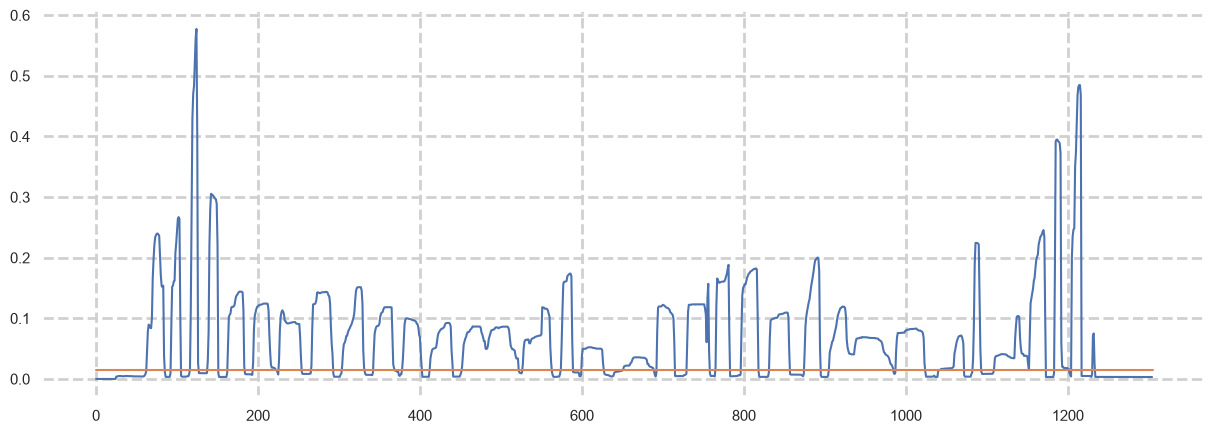

In [22]:
trial_data = p5u.split_preprocessed_pn(tgts4, preds4, thrsh = 0.015,plot_thrsh=True)

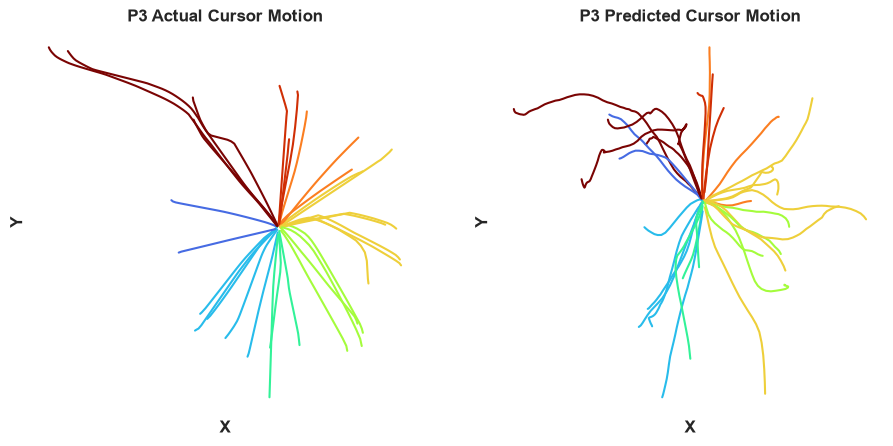

In [24]:
fix,ax = plt.subplots(1,2, figsize = (11,5))


for trial in range(trial_data['num_trials']):
    ## manually remove bad splits
    if(trial == 44):
        print(trial)
    else:
        ax[0].plot(  trial_data['x_values'][trial],trial_data['y_values'][trial], color=color_list[ trial_data['angle_bins'][trial]] )

    ax[0].set_title("P3 Actual Cursor Motion",fontweight = 'bold')
    ax[0].set_xlabel("X",fontweight = 'bold')
    ax[0].set_ylabel("Y",fontweight = 'bold')
    ax[0].set_xticks([])
    ax[0].set_yticks([])

for trial in range(trial_data['num_trials']):
    ## manguall remove bad splits
    if(trial == 44 ):
        print(trial)
    else:
        ax[1].plot(  trial_data['x_hat_values'][trial],trial_data['y_hat_values'][trial], color=color_list[ trial_data['angle_bins'][trial]] )

    ax[1].set_title("P3 Predicted Cursor Motion", fontweight = 'bold')
    ax[1].set_xlabel("X",fontweight = 'bold')
    ax[1].set_ylabel("Y",fontweight = 'bold')
    ax[1].set_xticks([])
    ax[1].set_yticks([])

In [5]:
trial_data = p5u.split_preprocessed_pn(tgts5, preds5, thrsh = 0.02,plot_thrsh=False)

44
44


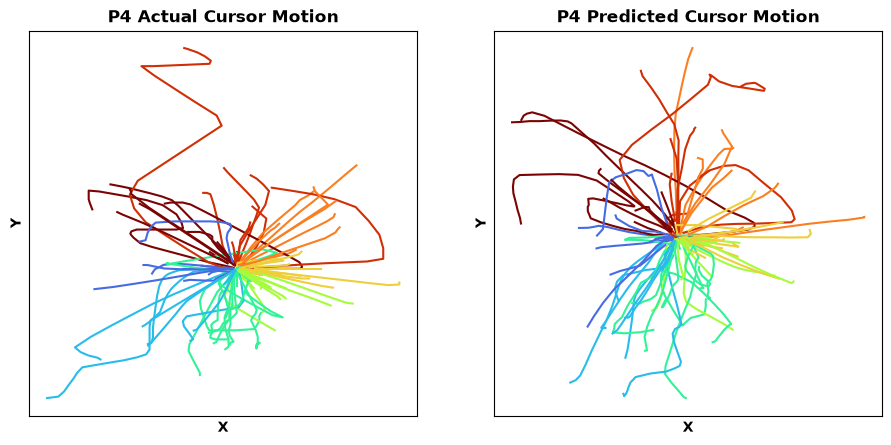

In [9]:
fix,ax = plt.subplots(1,2, figsize = (11,5))


for trial in range(trial_data['num_trials']):
    ## manually remove bad splits
    if(trial == 44):
        print(trial)
    else:
        ax[0].plot(  trial_data['x_values'][trial],trial_data['y_values'][trial], color=color_list[ trial_data['angle_bins'][trial]] )

    ax[0].set_title("P4 Actual Cursor Motion",fontweight = 'bold')
    ax[0].set_xlabel("X",fontweight = 'bold')
    ax[0].set_ylabel("Y",fontweight = 'bold')
    ax[0].set_xticks([])
    ax[0].set_yticks([])

for trial in range(trial_data['num_trials']):
    ## manguall remove bad splits
    if(trial == 44 ):
        print(trial)
    else:
        ax[1].plot(  trial_data['x_hat_values'][trial],trial_data['y_hat_values'][trial], color=color_list[ trial_data['angle_bins'][trial]] )

    ax[1].set_title("P4 Predicted Cursor Motion", fontweight = 'bold')
    ax[1].set_xlabel("X",fontweight = 'bold')
    ax[1].set_ylabel("Y",fontweight = 'bold')
    ax[1].set_xticks([])
    ax[1].set_yticks([])

Text(0, 0.5, 'Y')

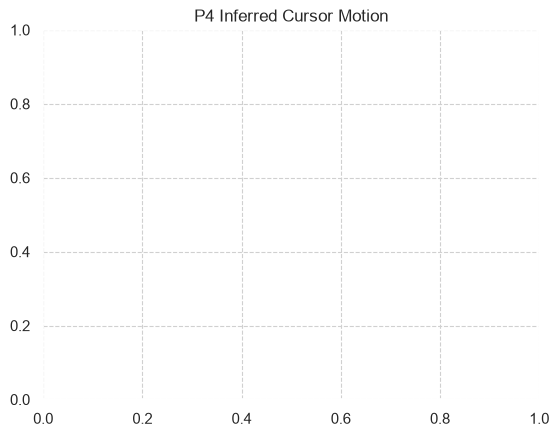

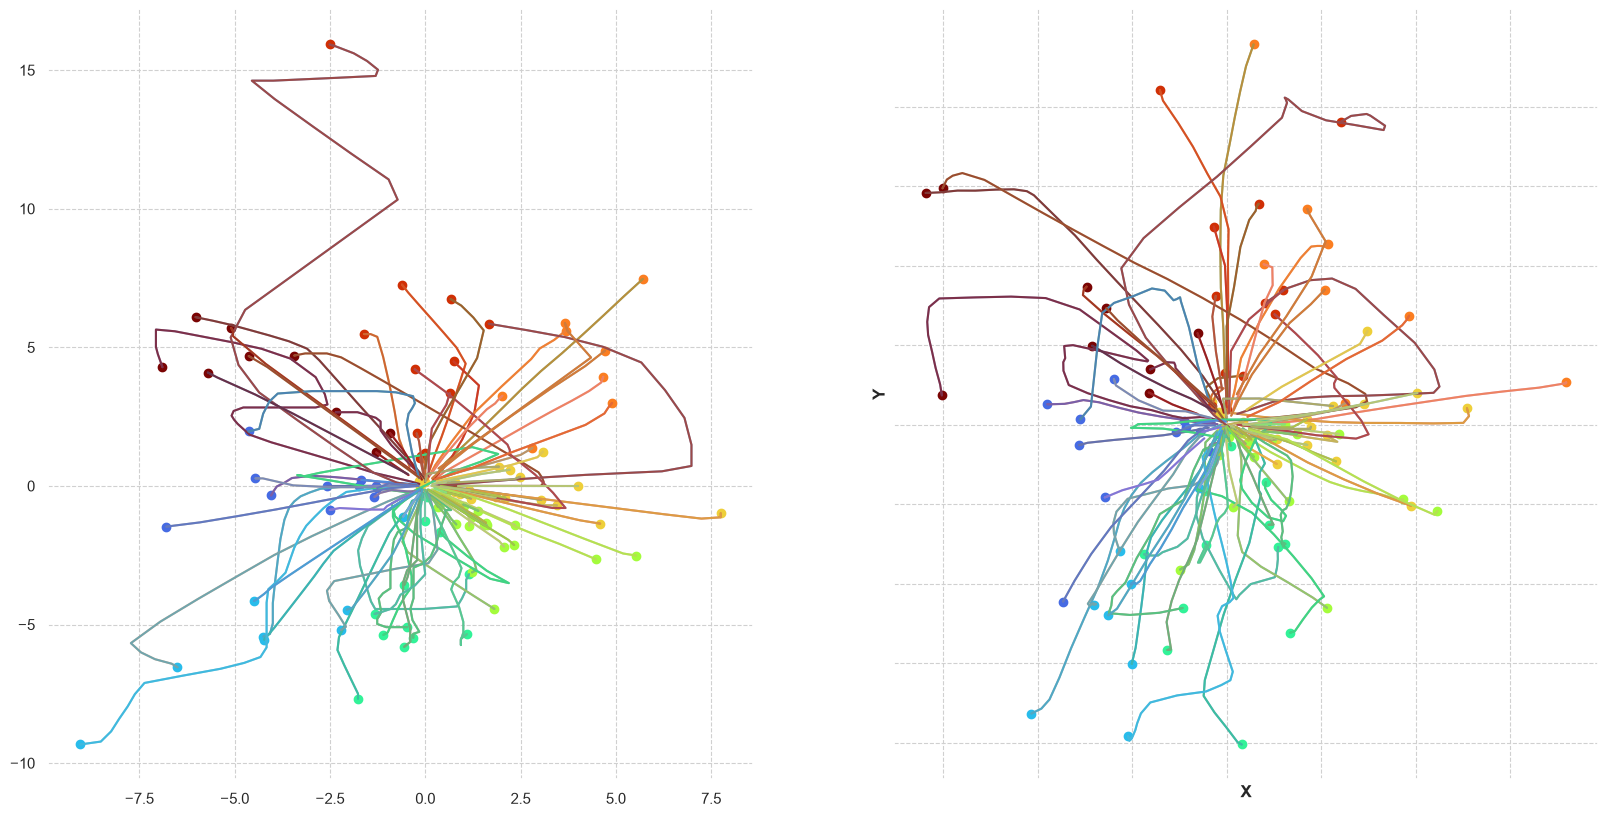

In [12]:
sns.set_theme(style="darkgrid")
sns.set(rc={
    "axes.facecolor": "#FFFFFF"  # change this to any color you want
})

plt.rcParams['grid.color'] = '#d0d0d0'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.linewidth'] = 0.8
plt.title("P4 Inferred Cursor Motion")

fig,ax = plt.subplots(1,2, figsize=(20,10))
ax[1].set_yticks(np.arange(-10,10,2))
#ax[1].set_xticks([0,500,1000,1500,2000,2500,3000,3500])

zeropt = [1125,285]
width = 500

for trial in range(trial_data['num_trials']):
    if (trial != None):
        x = trial_data['x_values'][trial]
        y = trial_data['y_values'][trial]

        x_ = trial_data['x_hat_values'][trial]
        y_ = trial_data['y_hat_values'][trial]

        angle = 180/np.pi* np.atan2(  y[-1] - y[0], x[-1] - x[0] ) 
        angle_class = int( np.rint(angle / 45) + 4)
        if angle_class == 8:
                angle_class = 0

        ax[0].plot(x,y)
        ax[0].plot(x, y, color=color_list[angle_class], alpha = 0.6 ) 
        ax[0].scatter(x[-1], y[-1], color=color_list[angle_class], alpha = 1 )
        
        ax[1].plot(x_,y_)
        ax[1].plot(x_, y_, color=color_list[angle_class], alpha = 0.6 ) 
        ax[1].scatter(x_[-1], y_[-1], color=color_list[angle_class], alpha = 1 )

    #ax[1].plot(x_,y_)
    #print(x)

plt.rcParams['grid.color'] = '#d0d0d0'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.linewidth'] = 2
#plt.title("P4 Inferred Cursor Motion")

plt.tick_params(
    axis='x',          # changes apply to the x-axis
    which='both',      # both major and minor ticks are affected
    bottom=False,      # ticks along the bottom edge are off
    top=False,         # ticks along the top edge are off
    labelbottom=False) # labels along the bottom edge are off
plt.tick_params(
    axis='y',          # changes apply to the x-axis
    which='both',      # both major and minor ticks are affected
    left=False,        # ticks along the bottom edge are off
    right=False,        # ticks along the top edge are off
    labelleft=False) # labels along the bottom edge are off
plt.xlabel("X", weight="bold")
plt.ylabel("Y", weight="bold")

# Figure 2m

(400,) (1074, 2) (400,)


Text(0.5, 1.0, 'P4 Pseudo-Online Inference')

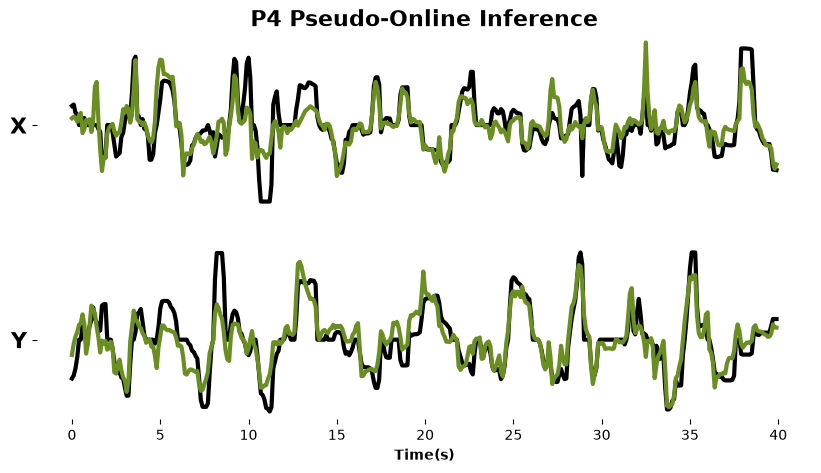

In [4]:
fig,ax = plt.subplots(2,1,figsize=(10,5))
fs = 10
t1 = 0
t2= 40*fs

ts = np.arange(0,(t2-t1)/fs, 1/fs)
print(np.shape(ts), np.shape(tgts5), np.shape(tgts5[t1:t2,0]))


ax[0].plot(ts,tgts5[t1:t2,0], linewidth=3,label="Joystick Position", color='black')
ax[0].plot(ts,preds5[t1:t2,0],label="Cursor Velocity", linewidth=3,color='olivedrab')
ax[0].set_yticks([])
#ax[0].legend(loc = "lower left")
ax[0].set_xticklabels([])
ax[0].grid(False)
ax[0].set_facecolor('#ffffff')
ax[0].set_yticks([0])
ax[0].set_yticklabels(["X"], weight="bold",fontsize=16)
ax[0].set_xticks([])
ax[0].set_frame_on(False)


ax[1].plot(ts,tgts5[t1:t2,1], label="Joystick Position", linewidth=3, color='black')
ax[1].plot(ts,preds5[t1:t2,1],label="Cursor Velocity", linewidth=3,color='olivedrab')
ax[1].set_yticks([])
ax[1].set_xlabel("Time(s)", weight="bold")
#ax[1].set_xticks(np.arange(0,t2+1,10))
#ax[1].set_xticklabels([0,"",20,"",40,"",60,"",80], fontsize=14)
ax[1].grid(False)
ax[1].set_facecolor('#ffffff')
ax[1].set_yticks([0])
ax[1].set_yticklabels(["Y"], weight="bold", fontsize=16)
ax[1].set_frame_on(False)

#fig.supylabel("P4 Simulated Inference", weight="bold", fontsize=16)

ax[0].set_title("P4 Pseudo-Online Inference", weight="bold",fontsize=16)

# Figure

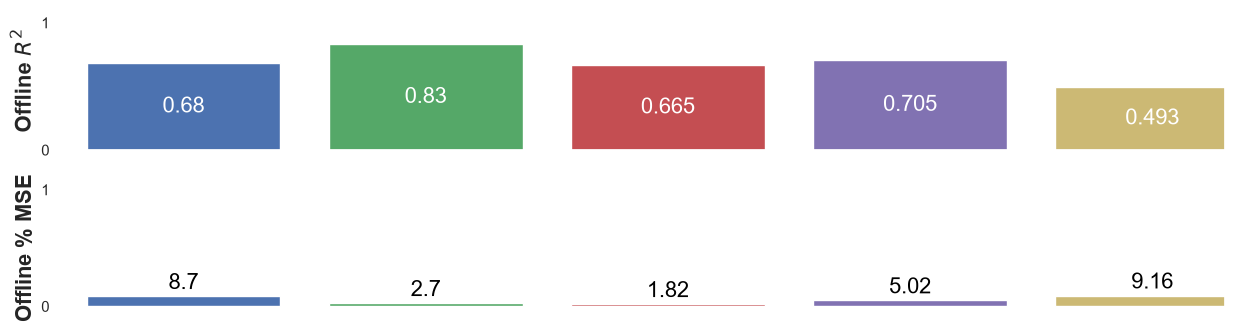

In [26]:
# cached results for consistency in the figure
offline_r2 = [0.68, 0.83, 0.665, 0.705, 0.493]
offline_mse = np.asarray([0.087, 0.027, 0.0182, 0.0502, 0.0916] )
participants = [1,2,3,4,5]
color_set =  ['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974']


fig,ax = plt.subplots(2,1, figsize = (15,4))

ax0_bars = ax[0].bar(participants,offline_r2, color=color_set)

for bar in ax0_bars:
    height = bar.get_height()
    ax[0].text(
        bar.get_x() + bar.get_width() / 2,
        height / 2,                  # inside the bar
        f'{height}',
        ha='center',
        va='center',
        color='white',
        fontsize=16
    )


ax[0].set_xticks([1,2,3,4,5] )
ax[0].set_xticks([])
ax[0].set_ylim(0,1.1)
ax[0].set_yticks([0,0.25, 0.5, 0.75, 1])
ax[0].set_yticklabels(["0","", "", "", "1"])
ax[0].set_ylabel(r'Offline $R^2$',fontsize=16, weight="bold")
ax[0].set_xlim([0.5,5.3] )
ax[0].grid(False)

#-------------------------------------
ax1_bars = ax[1].bar(participants,offline_mse, color=color_set)

for bar in ax1_bars:
    height = bar.get_height()
    ax[1].text(
        bar.get_x() + bar.get_width() / 2,
        height+0.2,                  # inside the bar
        f'{np.round(100*height, 3)}',
        ha='center',
        va='top',
        color='black',
        fontsize=16
    )



ax[1].set_xticks([1,2,3,4,5] )
ax[1].set_xticks([])
ax[1].set_ylim(-0.1,1.1)
ax[1].set_yticks([0,0.25, 0.5, 0.75, 1])
ax[1].set_yticklabels(["0","", "", "", "1"])
ax[1].set_ylabel(r"Offline % MSE", fontsize=16, weight='bold')
ax[1].set_xlim([0.5,5.3] )
ax[1].grid(False)
